# Vẽ ma trận nhầm lẫn và đường cong ROC cho mô hình dự đoán ung thư phổi (mục 4.3.4)

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)
DATA = Path('..') / 'data'   # thư mục data/

Tiền xử lý giống notebook 09: chuẩn hóa tên cột, xóa dòng trùng, mã hóa về 0/1

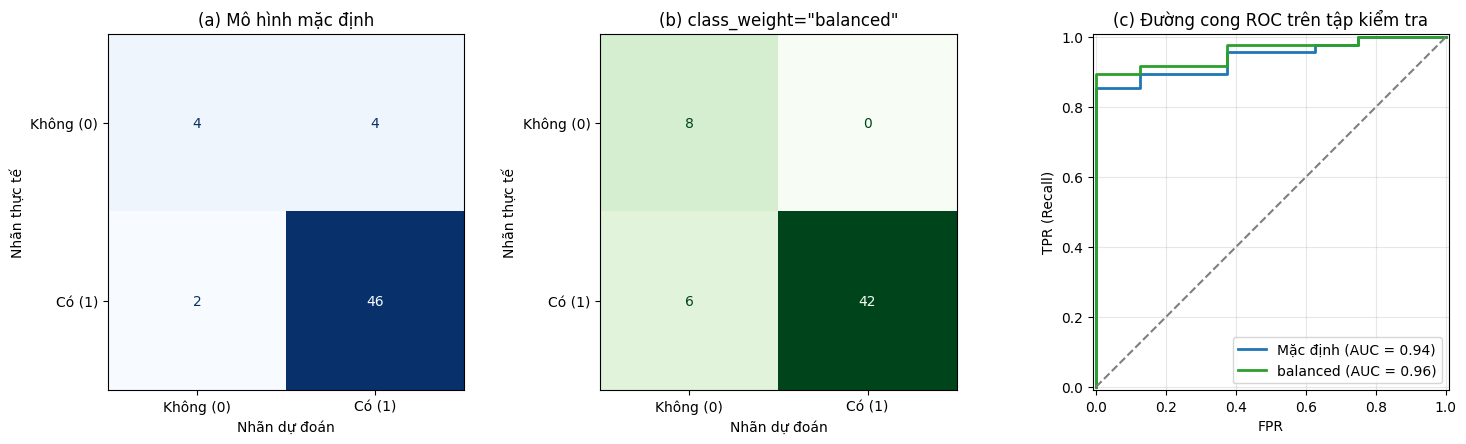

In [2]:
df = pd.read_csv(DATA / "survey lung cancer.csv")
df.columns = df.columns.str.strip()
df = df.drop_duplicates()
df["GENDER"] = (df["GENDER"] == "M").astype(int)
df["LUNG_CANCER"] = (df["LUNG_CANCER"] == "YES").astype(int)
symptoms = df.columns.drop(["GENDER", "AGE", "LUNG_CANCER"])   # các cột triệu chứng
df[symptoms] = df[symptoms] - 1

X = df.drop(columns="LUNG_CANCER")
y = df["LUNG_CANCER"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
model_balanced = make_pipeline(StandardScaler(),   # có cân bằng trọng số lớp
                               LogisticRegression(class_weight="balanced", max_iter=1000)).fit(X_train, y_train)

labels = ["Không (0)", "Có (1)"]   # nhãn hiển thị cho hai lớp
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=labels,
                                      cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("(a) Mô hình mặc định")
ConfusionMatrixDisplay.from_estimator(model_balanced, X_test, y_test, display_labels=labels,
                                      cmap="Greens", colorbar=False, ax=axes[1])
axes[1].set_title('(b) class_weight="balanced"')
for ax in axes[:2]:
    ax.set_xlabel("Nhãn dự đoán"); ax.set_ylabel("Nhãn thực tế")
RocCurveDisplay.from_estimator(model, X_test, y_test, name="Mặc định", ax=axes[2], curve_kwargs=dict(color="#1F77B4", lw=2))
RocCurveDisplay.from_estimator(model_balanced, X_test, y_test, name="balanced", ax=axes[2], curve_kwargs=dict(color="#2CA02C", lw=2))
axes[2].plot([0, 1], [0, 1], "--", color="#7F7F7F")
axes[2].set_xlabel("FPR"); axes[2].set_ylabel("TPR (Recall)")
axes[2].set_title("(c) Đường cong ROC trên tập kiểm tra"); axes[2].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES / "lung_cancer.png", dpi=150)